# 01. Dataset composition and domain shift

This notebook characterizes the five tomato categories shared by PlantVillage and PlantDoc: Healthy, Early Blight, Late Blight, Bacterial Spot, and Septoria Leaf Spot. It records class counts, source metadata, illustrative images, and available leaf-group information before model development.

PlantVillage is the laboratory source domain; PlantDoc is the target domain used for field evaluation and later supervised domain adaptation. The galleries describe sample appearance, rather than quantifying the causes of domain shift. No model is trained here.

## Execution environment

The setup cell installs dataset and plotting dependencies and sets seed 42. Image access requires the Hugging Face sources; existing outputs can be read without downloading them.

In [1]:
%pip install -q datasets pandas matplotlib pillow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from datasets import load_dataset

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment setup completed.")

Environment setup completed.


## PlantVillage source and original partitions

The loaded Hugging Face `train` container contains 54,304 rows, including both original partitions in its `split` metadata column. Original partition indicators are retained for the five-class analysis.

In [2]:
plant_village = load_dataset(
    "geraldmc/plantvillage-full",
    split="train"
)

print(plant_village)
print("\nDataset features:")
print(plant_village.features)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00002.parquet:   0%|          | 0.00/402M [00:00<?, ?B/s]

data/train-00001-of-00002.parquet:   0%|          | 0.00/453M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
    num_rows: 54304
})

Dataset features:
{'image': Image(mode=None, decode=True), 'class_label': Value('string'), 'class_idx': Value('int32'), 'host': Value('string'), 'disease': Value('string'), 'split': Value('string'), 'leaf_id': Value('string'), 'leaf_grouped': Value('bool')}


### Target classes

The source contains 38 classes, including ten tomato classes. Five are mapped to the shared disease names. The printed indices identify positions in the sorted source class list; they are not the final model label IDs (0–4) stored in `data/splits/label_map.json`.

In [3]:
# Retrieve the original class names
all_class_names = sorted(set(plant_village["class_label"]))

# Identify tomato-related classes
tomato_classes = [
    (idx, name)
    for idx, name in enumerate(all_class_names)
    if name.startswith("Tomato___")
]

print(f"Total original classes: {len(all_class_names)}")
print(f"Tomato classes: {len(tomato_classes)}")

for idx, name in tomato_classes:
    print(f"{idx}: {name}")

Total original classes: 38
Tomato classes: 10
28: Tomato___Bacterial_spot
29: Tomato___Early_blight
30: Tomato___Late_blight
31: Tomato___Leaf_Mold
32: Tomato___Septoria_leaf_spot
33: Tomato___Spider_mites Two-spotted_spider_mite
34: Tomato___Target_Spot
35: Tomato___Tomato_Yellow_Leaf_Curl_Virus
36: Tomato___Tomato_mosaic_virus
37: Tomato___healthy


In [4]:
TARGET_CLASSES = {
    "Tomato___healthy": "Healthy",
    "Tomato___Early_blight": "Early Blight",
    "Tomato___Late_blight": "Late Blight",
    "Tomato___Bacterial_spot": "Bacterial Spot",
    "Tomato___Septoria_leaf_spot": "Septoria Leaf Spot",
}

missing = set(TARGET_CLASSES) - set(all_class_names)
assert not missing, f"Missing classes: {missing}"

target_ids = {
    all_class_names.index(original): standard
    for original, standard in TARGET_CLASSES.items()
}

print("\nSelected classes:")
for label_id, name in target_ids.items():
    print(f"{label_id}: {name}")


Selected classes:
37: Healthy
29: Early Blight
30: Late Blight
28: Bacterial Spot
32: Septoria Leaf Spot


### Laboratory class counts

The selected classes contain 6,706 original training images and 1,692 original test images. Counts range from 1,000 Early Blight images to 2,127 Bacterial Spot images across both partitions. Subsequent preparation divides the original training partition into Lab Train (5,365) and Lab Validation (1,341).

split,test,train
Class,,
Healthy,326,1265
Early Blight,200,800
Late Blight,382,1527
Bacterial Spot,424,1703
Septoria Leaf Spot,360,1411


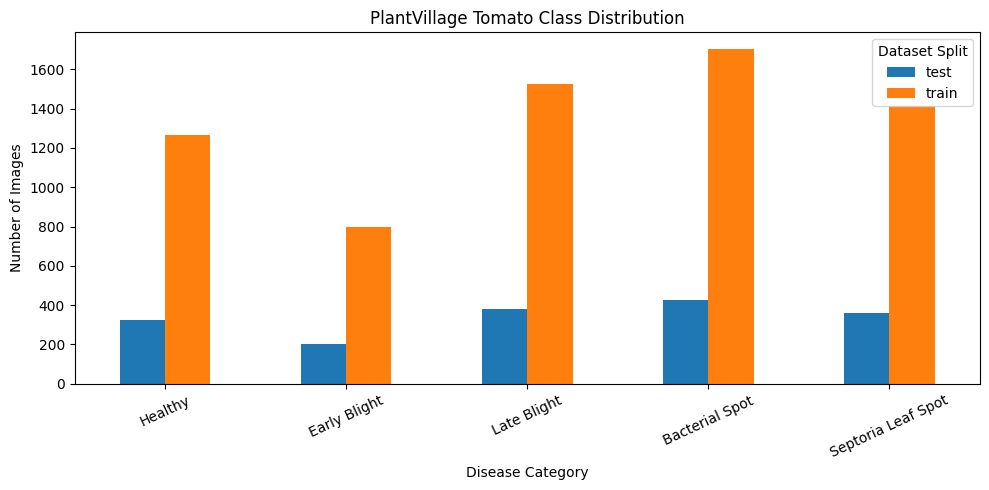

In [5]:
# Extract metadata without decoding images
metadata_df = pd.DataFrame({
    "class_label": plant_village["class_label"],
    "split": plant_village["split"]
})

# Filter the five target classes
metadata_df = metadata_df[
    metadata_df["class_label"].isin(TARGET_CLASSES)
].copy()

# Standardize class names
metadata_df["Class"] = metadata_df["class_label"].map(TARGET_CLASSES)

# Calculate class distribution across splits
summary = pd.crosstab(
    metadata_df["Class"],
    metadata_df["split"]
)

summary = summary.reindex(
    list(TARGET_CLASSES.values()),
    fill_value=0
)

display(summary)

# Visualize class distribution
summary.plot(kind="bar", figsize=(10, 5), rot=25)

plt.title("PlantVillage Tomato Class Distribution")
plt.xlabel("Disease Category")
plt.ylabel("Number of Images")
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

### Laboratory image examples

The gallery shows the first original training image in each target class. These five examples illustrate image composition; they are not a random sample or a systematic quality assessment.

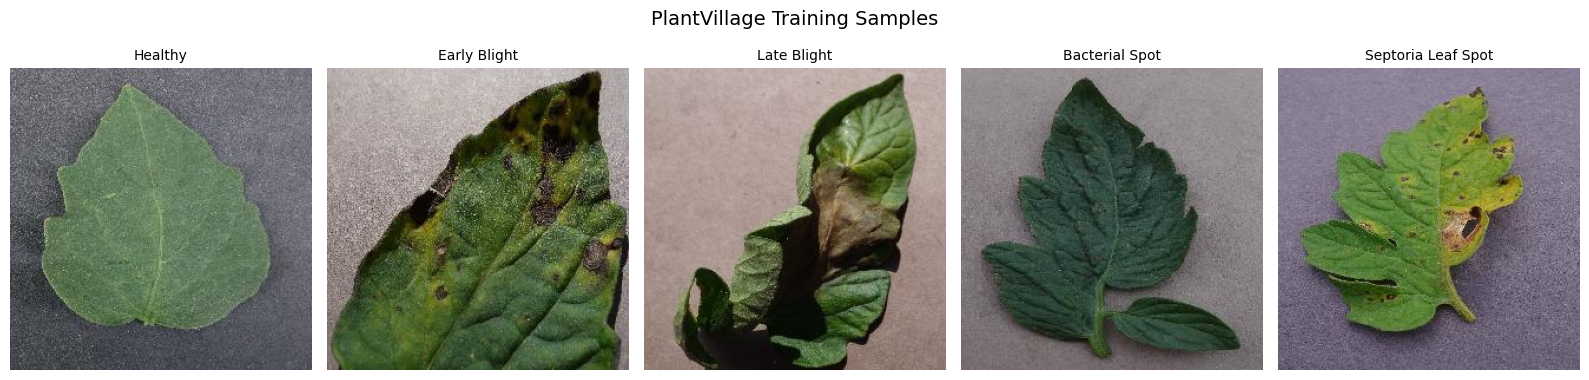

In [6]:
# Visualize one training image per target class
fig, axes = plt.subplots(1, len(TARGET_CLASSES), figsize=(16, 4))

for ax, (original_name, class_name) in zip(
    axes, TARGET_CLASSES.items()
):

    # Find images belonging to the current class in the train split
    candidates = metadata_df.index[
        (metadata_df["class_label"] == original_name)
        & (metadata_df["split"] == "train")
    ]

    assert len(candidates) > 0, f"No training image for {original_name}"

    # Retrieve the first matching image
    sample_idx = int(candidates[0])
    image = plant_village[sample_idx]["image"]

    ax.imshow(image)
    ax.set_title(class_name, fontsize=10)
    ax.axis("off")

plt.suptitle("PlantVillage Training Samples", fontsize=14)
plt.tight_layout()
plt.show()

## PlantDoc source and original partitions

The `v0.1.0` mirror loads 2,578 rows into one Hugging Face container. Original training and test membership is read from the `split` column, as for PlantVillage.

In [7]:
plant_doc = load_dataset(
    "geraldmc/plantdoc-full",
    revision="v0.1.0",
    split="train"
)

print(plant_doc)

print("\nDataset features:")
print(plant_doc.features)

print("\nTotal images:", len(plant_doc))

README.md:   0%|          | 0.00/542 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet:   0%|          | 0.00/476M [00:00<?, ?B/s]

data/train-00001-of-00002.parquet:   0%|          | 0.00/516M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2578 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'is_healthy', 'split', 'filename'],
    num_rows: 2578
})

Dataset features:
{'image': Image(mode=None, decode=True), 'class_label': Value('string'), 'class_idx': Value('int64'), 'host': Value('string'), 'disease': Value('string'), 'is_healthy': Value('bool'), 'split': Value('string'), 'filename': Value('string')}

Total images: 2578


### Label harmonization and field counts

Five source labels are mapped to the shared class names while preserving source `row_id`. This defines a common nominal classification task; it does not establish that all labels are correct.

The selected subset contains 476 original training images and 47 original Field Test images (523 total). The verified adaptation protocol introduced later partitions the 476 training rows into Field Adapt Train (370), Field Dev (92), and quarantine (14).

In [8]:
PLANTDOC_LABEL_MAP = {
    "Tomato leaf": "Healthy",
    "Tomato Early blight leaf": "Early Blight",
    "Tomato leaf late blight": "Late Blight",
    "Tomato leaf bacterial spot": "Bacterial Spot",
    "Tomato Septoria leaf spot": "Septoria Leaf Spot",
}

# Validate the class mapping
available_labels = set(plant_doc["class_label"])
missing_labels = set(PLANTDOC_LABEL_MAP) - available_labels

assert not missing_labels, f"Missing labels: {missing_labels}"
assert set(PLANTDOC_LABEL_MAP.values()) == set(TARGET_CLASSES.values())

# Preserve original dataset row indices
field_metadata_df = pd.DataFrame({
    "row_id": np.arange(len(plant_doc)),
    "class_label": plant_doc["class_label"],
    "split": plant_doc["split"]
})

# Select and standardize target classes
field_df = field_metadata_df[
    field_metadata_df["class_label"].isin(PLANTDOC_LABEL_MAP)
].copy()

field_df["Class"] = field_df["class_label"].map(
    PLANTDOC_LABEL_MAP
)

class_order = list(TARGET_CLASSES.values())

# Calculate class distribution
field_summary = pd.crosstab(
    field_df["Class"],
    field_df["split"]
).reindex(
    index=class_order,
    columns=["train", "test"],
    fill_value=0
)

field_summary["Total"] = field_summary.sum(axis=1)

display(field_summary)

print("Selected field images:", len(field_df))

split,train,test,Total
Class,,,
Healthy,55,8,63
Early Blight,79,9,88
Late Blight,101,10,111
Bacterial Spot,101,9,110
Septoria Leaf Spot,140,11,151


Selected field images: 523


### Paired laboratory and field examples

One training image per class is sampled from each source with seed 42. The comparison examines background, illumination, and composition. Field Test images are excluded from this gallery; that partition was subsequently inspected in the baseline evaluation recorded in notebook 04.

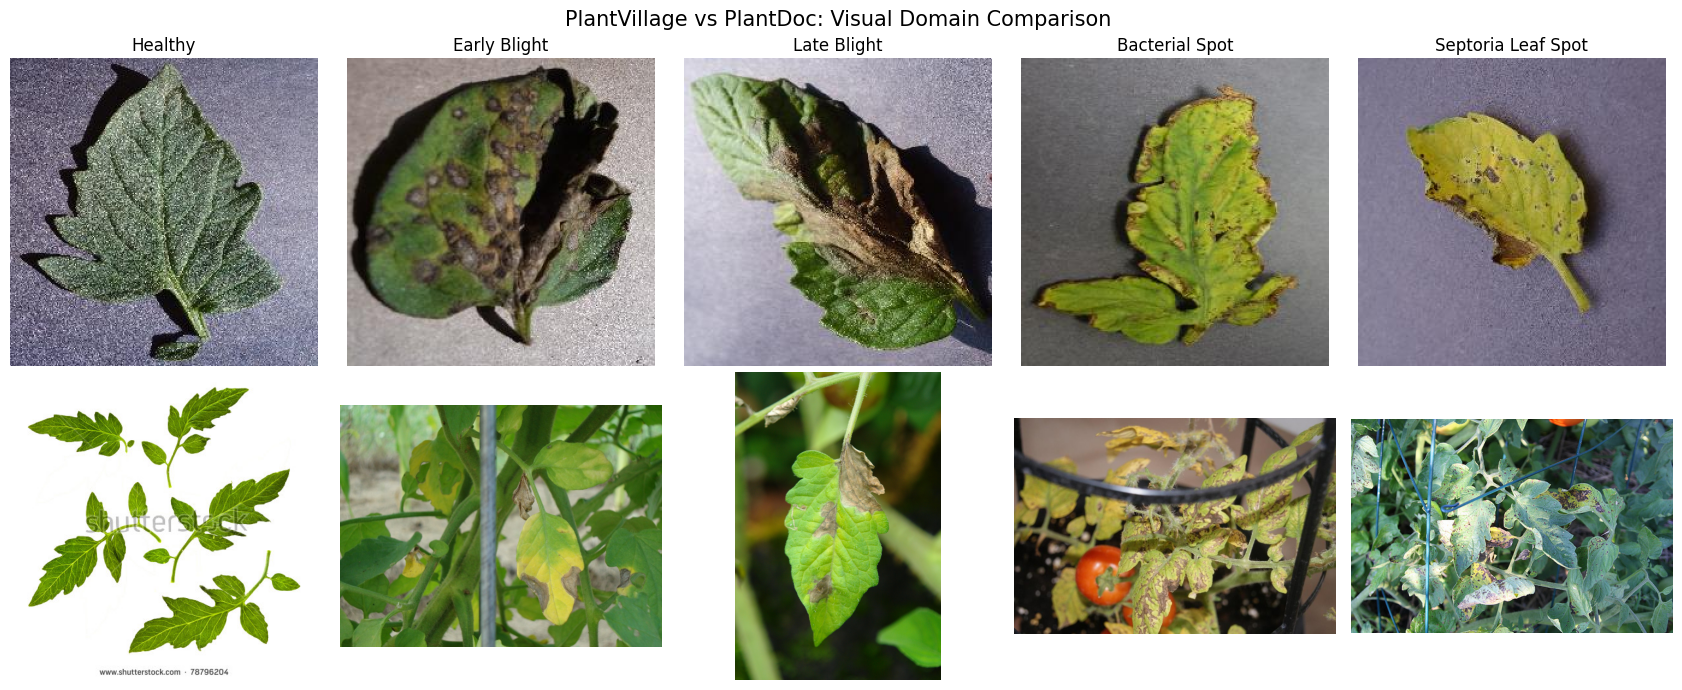

In [9]:
fig, axes = plt.subplots(
    2, len(class_order), figsize=(17, 7)
)

rng = np.random.default_rng(RANDOM_SEED)

for col, class_name in enumerate(class_order):

    # Select one laboratory training image
    lab_indices = metadata_df.index[
        (metadata_df["Class"] == class_name)
        & (metadata_df["split"] == "train")
    ]

    # Select one field training image
    field_indices = field_df.loc[
        (field_df["Class"] == class_name)
        & (field_df["split"] == "train"),
        "row_id"
    ]

    assert len(lab_indices) > 0
    assert len(field_indices) > 0

    lab_idx = int(rng.choice(lab_indices))
    field_idx = int(rng.choice(field_indices))

    lab_image = plant_village[lab_idx]["image"].convert("RGB")
    field_image = plant_doc[field_idx]["image"].convert("RGB")

    axes[0, col].imshow(lab_image)
    axes[0, col].set_title(class_name)

    axes[1, col].imshow(field_image)

    axes[0, col].axis("off")
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Lab", fontsize=13)
axes[1, 0].set_ylabel("Field", fontsize=13)

plt.suptitle(
    "PlantVillage vs PlantDoc: Visual Domain Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Sample composition across domains

The five-class totals are 8,398 PlantVillage and 523 PlantDoc images. Relative class frequencies describe these dataset samples, not disease prevalence in an agricultural population. Septoria Leaf Spot contributes 151 of the 523 PlantDoc images.

,PlantVillage (Lab),PlantDoc (Field)
Class,,
Healthy,1591,63
Early Blight,1000,88
Late Blight,1909,111
Bacterial Spot,2127,110
Septoria Leaf Spot,1771,151


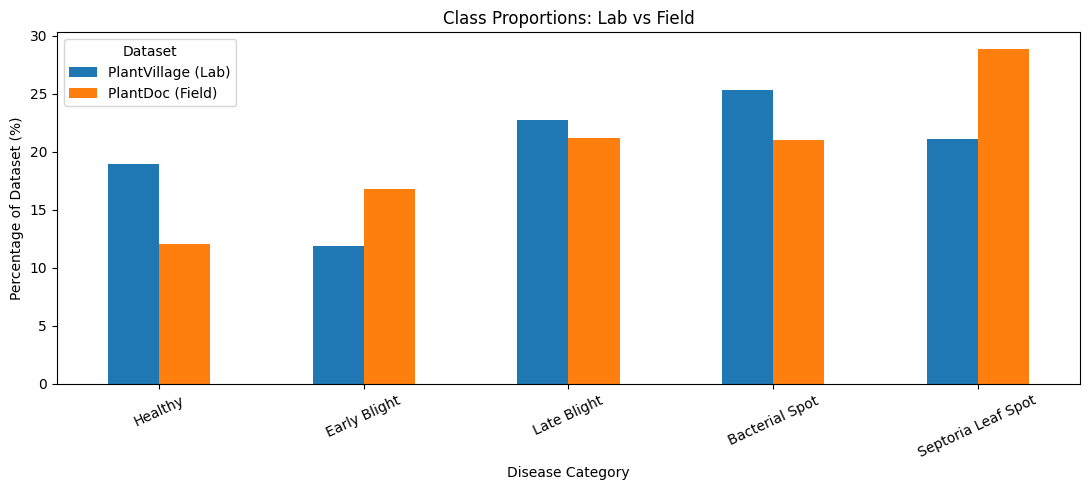

In [10]:
lab_counts = (
    metadata_df.groupby("Class")
    .size()
    .reindex(class_order, fill_value=0)
)

field_counts = (
    field_df.groupby("Class")
    .size()
    .reindex(class_order, fill_value=0)
)

comparison_df = pd.DataFrame({
    "PlantVillage (Lab)": lab_counts,
    "PlantDoc (Field)": field_counts
})

display(comparison_df)

# Normalize by dataset size to compare class proportions
class_percentages = (
    comparison_df.div(comparison_df.sum(axis=0), axis=1) * 100
)

class_percentages.plot(
    kind="bar",
    figsize=(11, 5),
    rot=25
)

plt.title("Class Proportions: Lab vs Field")
plt.xlabel("Disease Category")
plt.ylabel("Percentage of Dataset (%)")
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

### Implications for evaluation

Subsequent experiments use the same five-class label order and report macro-F1, accuracy, and per-class metrics. Split construction preserves original test membership and groups related training images before forming validation or development subsets. Source-domain validation and target-domain development are reported separately.

## Leaf-group coverage and partition overlap

Among the selected PlantVillage images, reliable grouping metadata covers 4,818 original training and 1,227 original test images. The remaining 1,888 training and 465 test images lack reliable groups. The saved check finds 1,512 reliable leaf groups and no overlap of those groups across original partitions; it cannot establish separation for the ungrouped images.

In [11]:
# Retrieve metadata for the selected PlantVillage classes
lab_quality_df = pd.DataFrame({
    "row_id": np.arange(len(plant_village)),
    "class_label": plant_village["class_label"],
    "split": plant_village["split"],
    "leaf_id": plant_village["leaf_id"],
    "leaf_grouped": plant_village["leaf_grouped"],
})

lab_quality_df = lab_quality_df[
    lab_quality_df["class_label"].isin(TARGET_CLASSES)
].copy()

# Examine the availability of original leaf groups
print("Leaf grouping information:")
display(pd.crosstab(
    lab_quality_df["split"],
    lab_quality_df["leaf_grouped"]
))

# Check overlap of reliable leaf IDs
grouped = lab_quality_df[
    lab_quality_df["leaf_grouped"] == True
]

train_leaf_ids = set(
    grouped.loc[grouped["split"] == "train", "leaf_id"]
)

test_leaf_ids = set(
    grouped.loc[grouped["split"] == "test", "leaf_id"]
)

overlap = train_leaf_ids & test_leaf_ids

print("Overlapping leaf groups:", len(overlap))
print("Unique reliable leaf groups:", grouped["leaf_id"].nunique())

Leaf grouping information:


leaf_grouped,False,True
split,,
test,465,1227
train,1888,4818


Overlapping leaf groups: 0
Unique reliable leaf groups: 1512


## Field image quality examples

The final gallery samples four original PlantDoc training images per class with seed 42. It supports inspection for watermarks, ambiguous symptoms, and heterogeneous backgrounds. No adjudicated labels or image exclusions are recorded by this cell; later quarantine decisions are documented by the verified split protocol.

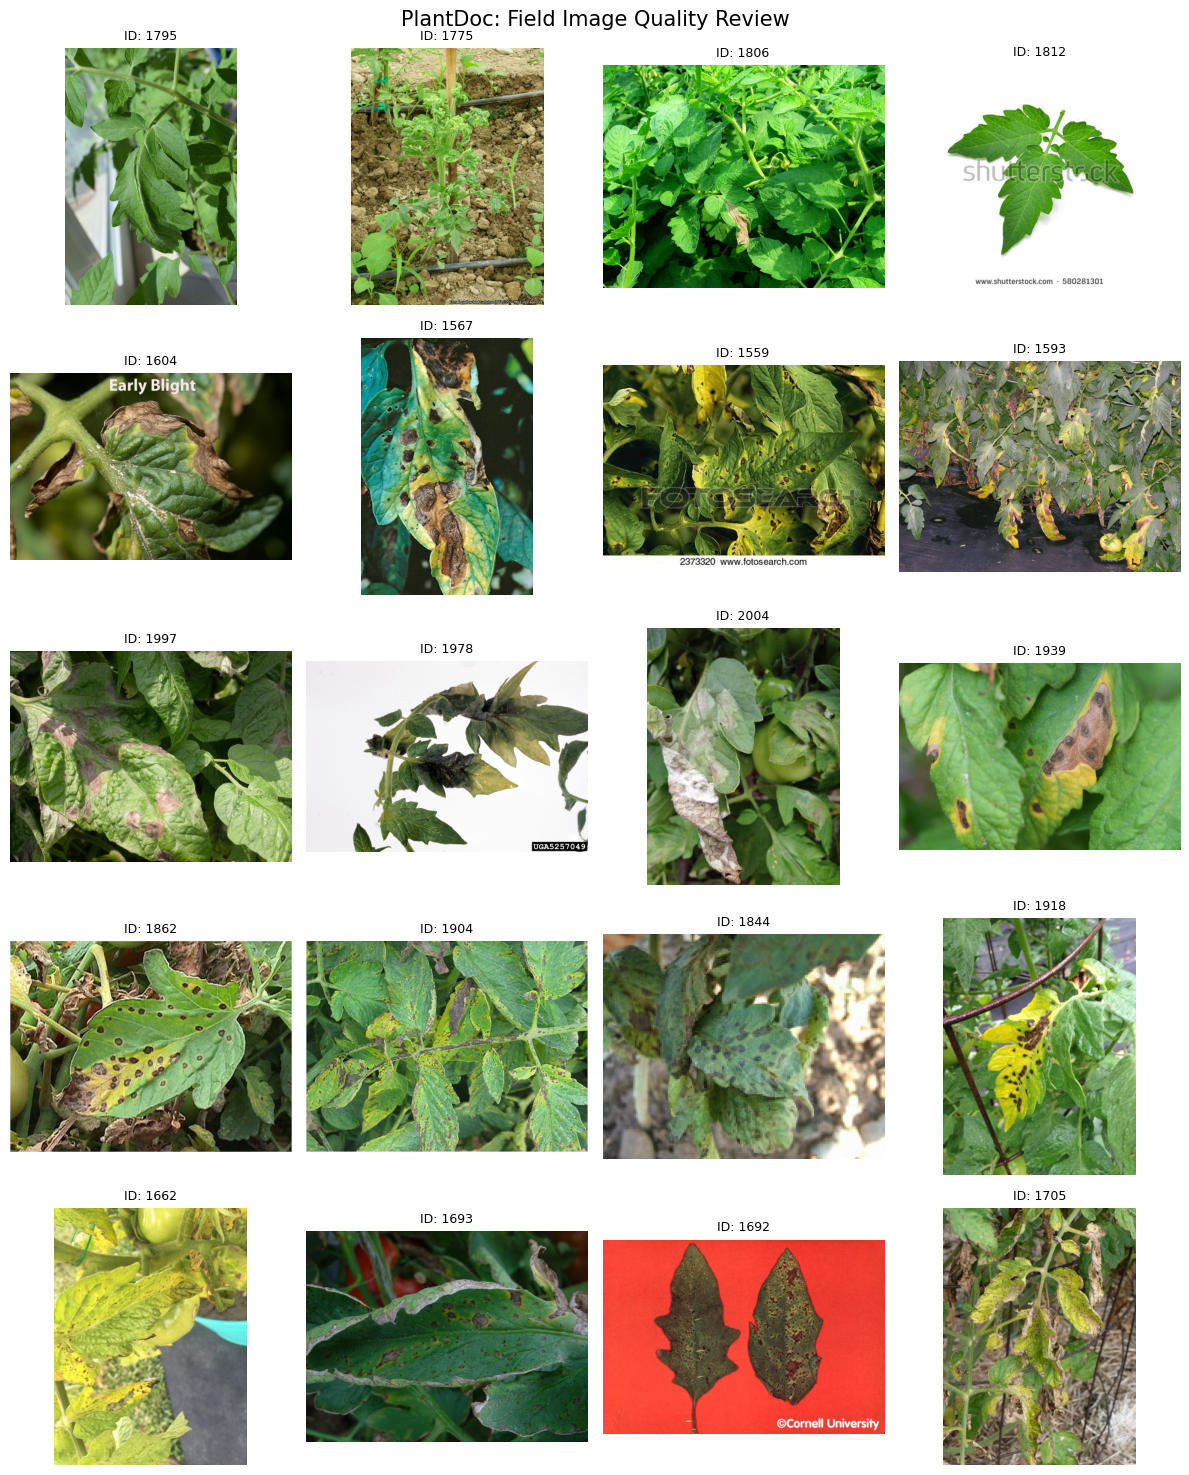

In [12]:
rng = np.random.default_rng(42)
n_samples = 4

fig, axes = plt.subplots(
    len(class_order),
    n_samples,
    figsize=(12, 15)
)

for row, class_name in enumerate(class_order):

    candidates = field_df.loc[
        (field_df["Class"] == class_name)
        & (field_df["split"] == "train"),
        "row_id"
    ].to_numpy()

    selected = rng.choice(
        candidates,
        size=min(n_samples, len(candidates)),
        replace=False
    )

    for col, idx in enumerate(selected):
        image = plant_doc[int(idx)]["image"].convert("RGB")
        axes[row, col].imshow(image)
        axes[row, col].axis("off")
        axes[row, col].set_title(f"ID: {idx}", fontsize=9)

    axes[row, 0].set_ylabel(
        class_name,
        fontsize=11
    )

plt.suptitle("PlantDoc: Field Image Quality Review", fontsize=15)
plt.tight_layout()
plt.show()